# Практическое занятие №13–14: кластеризация KMeans
Три пункта задания: кластеризация вин, сжатие изображений, кластеризация текстов, плюс разбор примера из теории — KMeans на синтетике `make_blobs`.

In [1]:
# Окружение и воспроизводимость: фиксируем SEED=17 для всех алгоритмов ниже.
# DejaVu Sans — русские подписи на графиках без «квадратиков».
import warnings
warnings.filterwarnings("ignore")  # гасим ConvergenceWarning KMeans и UserWarning библиотек
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.rcParams["font.family"] = "DejaVu Sans"
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.datasets import make_blobs
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             homogeneity_score, completeness_score, v_measure_score)
from sklearn.preprocessing import StandardScaler
import sklearn
SEED = 17
print("python:", sys.version.split()[0], "| sklearn:", sklearn.__version__,
      "| numpy:", np.__version__, "| pandas:", pd.__version__)


python: 3.11.13 | sklearn: 1.9.1 | numpy: 2.4.6 | pandas: 3.1.0


## 0. Пример из теории: KMeans на `make_blobs`
Синтетика вместо датасета NBA: 300 точек вокруг 5 центров. KMeans чередует E-шаг (отнести точку к ближайшему центру) и M-шаг (пересчёт центров как средних), минимизируя `inertia_` — сумму квадратов расстояний до своего центра.

точек: 300 | inertia_: 597.55


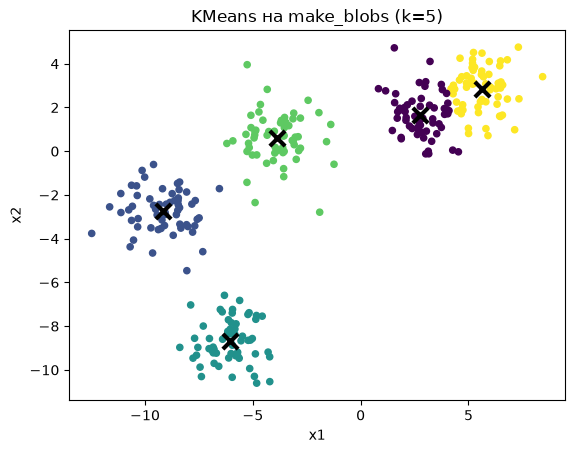

In [2]:
# Синтетика: 300 точек, 5 центров, разброс std=1.0 — истинные метки yb знаем, но KMeans их не видит.
# KMeans(n_clusters=5, n_init=10): 10 запусков с разных стартов, побеждает запуск с меньшей inertia_.
Xb, yb = make_blobs(n_samples=300, centers=5, cluster_std=1.0, random_state=SEED)
km = KMeans(n_clusters=5, n_init=10, random_state=SEED)
pred = km.fit_predict(Xb)
print("точек:", Xb.shape[0], "| inertia_:", round(km.inertia_, 2))
# Диаграмма: цвет точки — найденный кластер, чёрные кресты — итоговые центры.
plt.figure()
plt.scatter(Xb[:, 0], Xb[:, 1], c=pred, s=20)
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
            marker="x", s=120, linewidths=3, color="black")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("KMeans на make_blobs (k=5)")
plt.savefig("blobs_kmeans.png")
plt.show()


## 1. Кластеризация вин: `init='k-means++'` против `init='random'`
Данные — `winequality-red.csv` (1599 вин, 11 physicо-химических признаков). Признаки стандартизуем (`StandardScaler`: $z=(x-\mu)/\sigma$), иначе евклидово расстояние захватит признак с самым большим масштабом. Качество бинаризуем: $\le 5$ → 0 «низкое», $>5$ → 1 «высокое» — это внешняя разметка для ARI.

In [3]:
# Загрузка: запятая-разделитель, 1599 строк; y_true — бинаризованное quality (0/1).
# StandardScaler обязателен: pH ~ 3, а total sulfur dioxide ~ десятки — без z-оценки KMeans
# мерил бы расстояние почти только по «большим» признакам.
df = pd.read_csv("winequality-red.csv")
X = df.drop(columns=["quality"]).values
y_true = (df["quality"].values > 5).astype(int)
Xs = StandardScaler().fit_transform(X)  # z-оценка по каждому признаку: (x - mean) / std
print("форма:", Xs.shape, "| доля quality>5:", round(y_true.mean(), 3))
# Два запуска k=2: k-means++ разбрасывает стартовые центры подальше друг от друга,
# random ставит их в случайные точки; n_init=10 в обоих — сравнение честное.
res = {}
for init in ["k-means++", "random"]:
    kmeans = KMeans(n_clusters=2, init=init, n_init=10, random_state=SEED)
    lab = kmeans.fit_predict(Xs)
    # inertia_ — компактность (меньше лучше); silhouette в [-1, 1] — отделённость (больше лучше);
    # ARI — согласие с бинаризованным quality с поправкой на случай (1 — совпало).
    res[init] = (kmeans.inertia_, silhouette_score(Xs, lab), adjusted_rand_score(y_true, lab), lab)
print(f"{'init':<10}{'inertia_':>10}{'silhouette':>12}{'ARI':>8}")
for init, (ine, sil, ari, _) in res.items():
    print(f"{init:<10}{ine:>10.1f}{sil:>12.4f}{ari:>8.4f}")
# Оба init сошлись к одному разбиению: ARI между их метками = 1.0 — k-means++ и random
# нашли один и тот же оптимум (n_init=10 сгладил разницу стартов); ARI ~ 0.03 к quality:
# два сгущения химии вин почти не связаны с порогом quality>5.
print("ARI между разбиениями:", round(adjusted_rand_score(res['k-means++'][3], res['random'][3]), 4))


форма: (1599, 11) | доля quality>5: 0.535


init        inertia_  silhouette     ARI
k-means++    14330.1      0.2139  0.0291
random       14330.1      0.2139  0.0291
ARI между разбиениями: 1.0


объяснённая дисперсия 2 компонент: 0.457


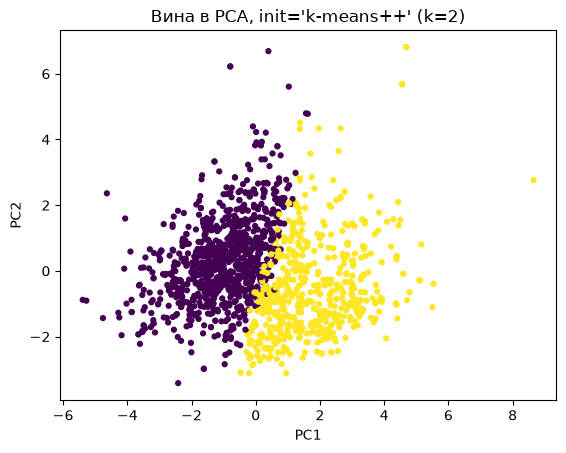

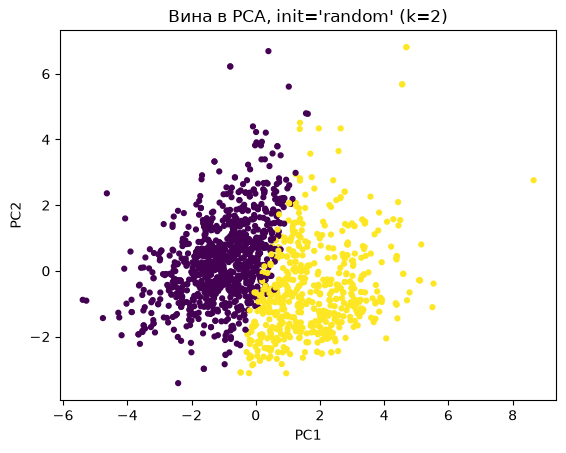

In [4]:
# PCA до 2 компонент — смотрим кластеры глазами: проекция на 2 оси максимальной дисперсии,
# раскраска точек — найденные метки кластера (не quality).
pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(Xs)
print("объяснённая дисперсия 2 компонент:", round(pca.explained_variance_ratio_.sum(), 3))
for init, fname in [("k-means++", "wine_kmeans_pp.png"), ("random", "wine_kmeans_rand.png")]:
    lab = res[init][3]
    plt.figure()
    plt.scatter(P[:, 0], P[:, 1], c=lab, s=12)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(f"Вина в PCA, init='{init}' (k=2)")
    plt.savefig(fname)
    plt.show()


## 2. Сжатие изображений через KMeans
Идея сжатия: пиксели — точки в пространстве цветов, $k$ центров — палитра. Каждый пиксель заменяем центром своего кластера: число цветов падает до $k$. Оба изображения генерируем программно через `numpy` (градиенты + круг).

размер: (100, 100) | байт: 80000 | цветов было: 100 стало: 3 | inertia_: 6283337.7


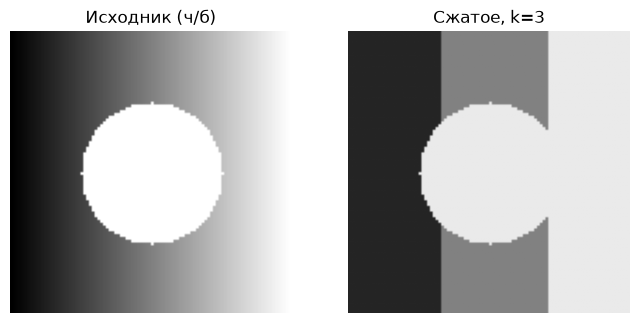

In [5]:
# Ч/б 100x100: горизонтальный градиент 0..255 + белый круг (r=25) в центре.
# MiniBatchKMeans(k=3) по яркости пикселя: 3 оттенка вместо ~100, круг и градиент сохраняются.
h = w = 100
yy, xx = np.mgrid[0:h, 0:w]  # сетки координат: xx растёт вправо, yy — вниз
gray = (xx / (w - 1) * 255).astype(float)  # градиент по x: слева 0, справа 255
gray[((xx - 50) ** 2 + (yy - 50) ** 2) <= 25 ** 2] = 255.0  # круг: точки с dist<=25 — белые
mb = MiniBatchKMeans(n_clusters=3, random_state=SEED).fit(gray.reshape(-1, 1))
small = mb.cluster_centers_[mb.labels_].reshape(h, w)  # замена пикселя центром его кластера
print("размер:", gray.shape, "| байт:", gray.nbytes,
      "| цветов было:", len(np.unique(gray)), "стало:", len(np.unique(mb.labels_)),
      "| inertia_:", round(mb.inertia_, 1))
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Исходник (ч/б)")
ax[0].axis("off")
ax[1].imshow(small, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Сжатое, k=3")
ax[1].axis("off")
plt.savefig("compress_gray.png")
plt.show()


размер: (100, 100, 3) | байт: 240000 | цветов было: 10000 стало: 8 | inertia_: 17820796.3


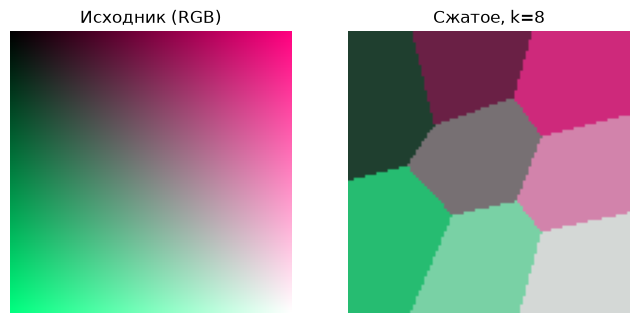

In [6]:
# Цветное 100x100x3: R — градиент по x, G — по y, B — диагональ; кластеризация в RGB-кубе, k=8.
R = np.tile(np.linspace(0, 255, w), (h, 1))  # строки-копии шкалы 0..255 по x
G = np.tile(np.linspace(0, 255, h), (w, 1)).T  # то же по y (транспонируем)
B = ((xx + yy) / (2 * (w - 1)) * 255)  # диагональ: 0 в углу, 255 в противоположном
rgb = np.stack([R, G, B], axis=-1)  # куб (100, 100, 3)
mbc = MiniBatchKMeans(n_clusters=8, random_state=SEED).fit(rgb.reshape(-1, 3))
flat = mbc.cluster_centers_[mbc.labels_].reshape(h, w, 3) / 255  # назад в [0, 1] для imshow
print("размер:", rgb.shape, "| байт:", rgb.nbytes,
      "| цветов было:", len(np.unique(rgb.reshape(-1, 3), axis=0)),
      "стало:", len(np.unique(mbc.labels_)),
      "| inertia_:", round(mbc.inertia_, 1))
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(rgb / 255)
ax[0].set_title("Исходник (RGB)")
ax[0].axis("off")
ax[1].imshow(np.clip(flat, 0, 1))
ax[1].set_title("Сжатое, k=8")
ax[1].axis("off")
plt.savefig("compress_rgb.png")
plt.show()


## 3. Кластеризация текстов без интернета
Вместо `fetch_20newsgroups` (нужен интернет) — встроенный мини-корпус: 40 фраз вручную, 4 темы по 10 фраз (спорт / космос / религия / графика, метки 0–3). Схема как в примере ТЗ: `TfidfVectorizer` (важность слова = частота во фразе × редкость по корпусу) → `KMeans(n_clusters=4)` → метрики согласия и топ-слов кластеров.

In [7]:
# Мини-корпус: 40 фраз, 4 темы по 10 (0 — спорт, 1 — космос, 2 — религия, 3 — графика).
# TfidfVectorizer: вес слова = частота во фразе (tf) × редкость по корпусу (idf) — матрица 40 × словарь.
docs = ["Матч завершился победой команды хозяев со счётом два ноль",
 "Нападающий команды забил гол на последней минуте матча",
 "Тренер заменил уставшего полузащитника команды после матча",
 "Вратарь отразил пенальти и спас команду в матче",
 "Команда выиграла чемпионат после решающего матча",
 "Защитник команды получил карточку за грубый подкат в матче",
 "Болельщики команды заполнили стадион перед финальным матчем",
 "Капитан вывел команду на решающий матч турнира",
 "Форвард забил победный гол команды в финальном матче",
 "Мяч команды пересёк линию ворот в конце матча",
 "Ракета вывела спутник на орбиту Земли",
 "Космонавт вышел в открытый космос с орбиты станции",
 "Телескоп обнаружил новую планету у далёкой звезды",
 "Марсоход передал снимки поверхности планеты",
 "Запуск ракеты отложили из-за сильного ветра",
 "Ракета доставила экипаж на орбиту станции",
 "Галактика содержит миллиарды звёзд и планет",
 "Спутник сошёл с орбиты и сгорел над планетой",
 "Орбита спутника проходит над экватором планеты",
 "Космос встретил экипаж ракеты за орбитой Луны",
 "Священник прочитал молитву в храме",
 "Паломники отправились к храму на праздник",
 "Монастырь хранит древние иконы храма",
 "Верующие зажгли свечи во время молитвы",
 "Священник произнёс проповедь о милосердии",
 "Храм украсили цветами к празднику",
 "Монах переписал текст молитвы",
 "Колокол храма созвал прихожан на молитву",
 "Прихожане поставили свечи за здравие близких",
 "Настоятель освятил новый иконостас храма",
 "Видеокарта ускорила рендеринг трёхмерной сцены",
 "Дизайнер настроил освещение сцены для рендеринга",
 "Пиксели текстуры растянулись на полигонах сцены",
 "Рендеринг кадра занял шестнадцать миллисекунд",
 "Художник нарисовал текстуру для персонажа сцены",
 "Трассировка лучей улучшила рендеринг теней",
 "Пиксель шейдера рассчитал блик на текстуре",
 "Аниматор настроил скелет модели для сцены",
 "Шейдеры ускорили рендеринг воды в сцене",
 "Пиксели экрана мерцают при быстром рендеринге"]
y_text = [0] * 10 + [1] * 10 + [2] * 10 + [3] * 10  # истинные темы — только для оценки
vec = TfidfVectorizer()
V = vec.fit_transform(docs)  # строки — фразы, столбцы — слова, значения — веса tf-idf
print("фраз:", V.shape[0], "| словарь:", V.shape[1])
kt_km = KMeans(n_clusters=4, n_init=10, random_state=SEED)
kt = kt_km.fit_predict(V)
# homogeneity — в кластере одна тема; completeness — тема лежит в одном кластере;
# v_measure — их среднее гармоническое; ARI — согласие с истиной с поправкой на случай.
print("homogeneity:", round(homogeneity_score(y_text, kt), 3))
print("completeness:", round(completeness_score(y_text, kt), 3))
print("v_measure:", round(v_measure_score(y_text, kt), 3))
print("ARI:", round(adjusted_rand_score(y_text, kt), 3))


фраз: 40 | словарь: 184
homogeneity: 0.522
completeness: 0.575
v_measure: 0.547
ARI: 0.397


In [8]:
# Топ-10 слов кластера: берём центр (средний tf-idf вектор), сортируем веса по убыванию.
# Как в примере ТЗ: характерные слова показывают, какую тему поймал каждый кластер.
terms = np.array(vec.get_feature_names_out())
order = kt_km.cluster_centers_.argsort(axis=1)[:, ::-1]  # индексы слов от большего веса к меньшему
for c in range(4):
    print(f"кластер {c}:", ", ".join(terms[order[c, :10]]))


кластер 0: храма, за, священник, молитву, молитвы, планеты, орбиты, свечи, над, космос
кластер 1: рендеринг, трёхмерной, ускорила, видеокарта, воды, сцене, теней, трассировка, улучшила, ускорили
кластер 2: команды, матча, после, гол, забил, матче, решающего, чемпионат, команда, выиграла
кластер 3: на, сцены, для, орбиту, ракета, настроил, пиксели, отправились, храму, праздник


## Вывод
KMeans нашёл 5 сгущений синтетики, сравнил два способа инициализации на винах (таблица `inertia_` / silhouette / ARI + проекции PCA), сжал ч/б и цветное изображения до 3 и 8 цветов и разложил 40 фраз мини-корпуса на 4 темы с оценкой homogeneity / completeness / V-меры / ARI и топ-словами кластеров. Результаты читаем честно: вина почти не делятся по бинаризованному quality (ARI ~ 0.03 — химия вин не сводится к двум сгущениям), фразы короткие, поэтому V-мера ~ 0.5, а топ-слова частично смешивают темы (ожидаемо для 40 фраз вместо 20 тысяч статей). Метод при этом отработан полностью: инициализации сравнены, сжатие показало падение числа цветов ровно до k, схема TF-IDF → KMeans → метрики/топ-слов повторяет пример ТЗ.